In [4]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import DBSCAN

from sklearn.decomposition import PCA
import umap.umap_ as umap
import pacmap

from utils.Preprocessing    import PreProcessData
from utils.plotFigures      import linePlot, lineAndScatterPlot, scatterPlot3D
from clustering.clusteringTimeSeries import ClusteringTimeSeries

# Preprocessing

In [5]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
df      = preData.splitTimeSeries()

scaler  = StandardScaler()
preData.normalizeData(scaler);

## Split time series graph

In [6]:
linePlot(df, x='tiempo', y='corriente(A)', color='trajectory')

# Clustering

In [7]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfManipulableVar = preData.scaledCrusher1[preData.manipulatedCr1]

clusteringModels    = {'pca':    DBSCAN(eps=0.9, min_samples=60), #, n_jobs=-1),
                       'umap':   DBSCAN(eps=2.4, min_samples=60), #, n_jobs=-1),
                       'pacmap': DBSCAN(eps=2.4, min_samples=60)} #, n_jobs=-1)} 

dimReductionModels  = {'pca':    PCA(n_components=3),
                       'umap':   umap.UMAP(n_components=3),
                       'pacmap': pacmap.PaCMAP(n_components=3)}

In [8]:
Clusters = ClusteringTimeSeries(data=preData.crusher1, 
                                dataNormalized=dfManipulableVar, 
                                clusteringModels=clusteringModels, 
                                dimReductionModels=dimReductionModels)

In [9]:
# import sys

# sys.argv.append("-Xfrozen_modules=off")

In [10]:
# Clusters are calculated
Clusters.getResults();

  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:30<00:00, 15.08s/it]


## Graphs of the results

### Comparison of clusters by dimensionality reduction algorithm

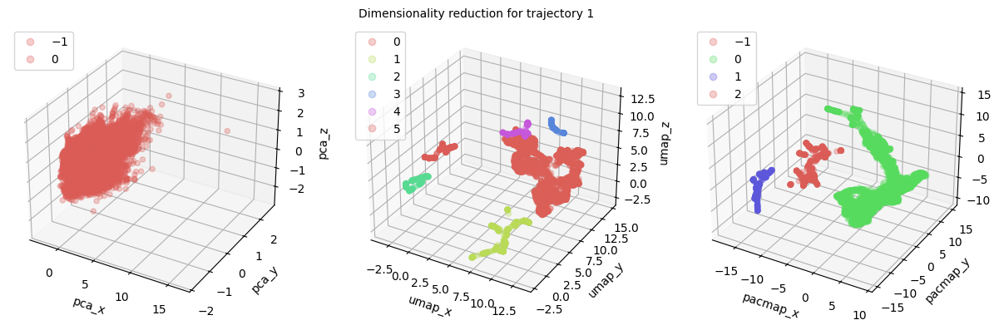

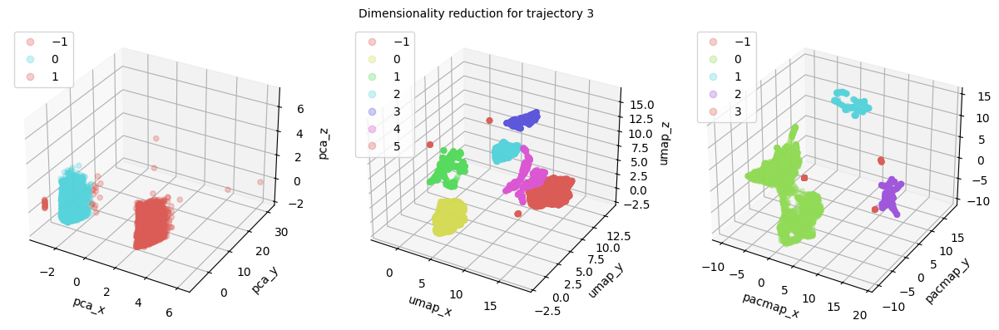

In [11]:
Clusters.subplotsScatter3D(2)

### Clusters in embedding space

In [23]:
Clusters.plotFigure('scatter3D', 
                    idxTrajectory=1, 
                    idxVariable=10, 
                    algorithm='pacmap')

### Time series colored by clusters

In [21]:
Clusters.plotFigure('lineplot', 
                    idxTrajectory=1, 
                    idxVariable=10, 
                    algorithm='pacmap')